# Indian Sign Language Recognition Using MobileNetV2

## 1. Introduction


Indian Sign Language (ISL) is an important communication medium for individuals who are deaf or hard of hearing. However, communication barriers can arise when people who do not understand sign language interact with ISL users.

The objective of this project is to develop a deep learning-based image classification system that can recognize Indian Sign Language signs from images and predict the corresponding sign category.

This project uses Convolutional Neural Networks (CNN) and Transfer Learning with MobileNetV2 to classify sign-language images into 24 different classes.

The model learns visual patterns from hand gestures and uses those patterns to predict the appropriate sign category

## 2. About the Dataset

he project dataset, provided as part of the DataMites project assignment, contains images representing different Indian Sign Language signs.

The images are organized into separate directories based on their respective sign classes. Each directory represents one classification category.

Dataset characteristics
Attribute	Description
Dataset name	PRAICP-1000-IndiSignLang
Data type	Image dataset
Classification type	Multiclass image classification
Number of classes	24
Input format	JPG, JPEG, PNG, BMP and WEBP
Image channels	RGB (3 channels)
Image dimensions used	224 × 224
Batch size	32

Dataset preparation
The dataset was loaded by identifying individual class folders and collecting the image paths.

Each class was assigned a unique numerical label using a class-to-index mapping.

This allowed the model to learn the relationship between the input images and their corresponding sign categories.
Dataset splitting
The dataset was divided using stratified sampling to maintain class representation across the three subsets.
Dataset	            Percentage	Purpose
Training	           70%	      Train the model
Validation	         15%	      Monitor performance during training
Testing	             15%	      Evaluate final model performance

Stratified splitting was used to maintain the distribution of sign classes across the datasets.

## 3. Process and Methodology
The project was implemented through the following stages

### Import required libraries

In [61]:
# 1. General utilities
import os
import zipfile
from pathlib import Path
from collections import Counter

# 2. Data manipulation and numerical operations
import numpy as np
import pandas as pd

# 3. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Deep learning and image processing
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

# 5. Transfer learning – MobileNetV2
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# 6. Model training callbacks
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# 7. Dataset splitting
from sklearn.model_selection import train_test_split

# 8. Model evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Display TensorFlow version
print("TensorFlow version:", tf.__version__)

Tensorflow version 2.21.0


### Dataset Loading
The Indian Sign Language dataset was extracted and loaded from the specified directory. The dataset contained images organized into separate folders, with each folder representing a particular sign category.

The dataset was loaded using Python's Path library. All class directories were identified, and image file paths were collected using supported image extensions such as JPG, JPEG, PNG, BMP and WEBP.

In [5]:
zip_path = Path("/content/PRAICP-1000-IndiSignLang.zip")
print("Zip file exists:",os.path.exists(zip_path))

Zip file exists: True


In [7]:
extract_path = "/content/IndiSignLang"
marker_path = os.path.join(extract_path, "_extraction_complete.txt")

if os.path.isfile(marker_path):
    print("Dataset already extracted. Skipping extraction.")

else:
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    # Verify that files were extracted
    extracted_files = [
        os.path.join(root, file)
        for root, _, files in os.walk(extract_path)
        for file in files
        if file != "_extraction_complete.txt"
    ]

    if extracted_files:
        with open(marker_path, "w") as f:
            f.write("Extraction completed")

        print("Extraction completed successfully!")
        print("Total extracted files:", len(extracted_files))
    else:
        print("No files found after extraction. Please check the ZIP.")

print("Dataset location:", extract_path)

Extraction completed successfully!
Total extracted files: 4972
Dataset location: /content/IndiSignLang


In [8]:
data_dir = Path("/content/IndiSignLang/Data")

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        images = list(folder.glob("*"))
        print(folder.name, ":", len(images))

print("Total classes:", len(list(data_dir.iterdir())))

A : 242
B : 259
C : 247
D : 147
E : 243
F : 226
G : 241
H : 116
I : 179
K : 245
L : 182
M : 235
N : 237
O : 229
P : 234
Q : 216
R : 211
S : 229
T : 216
U : 135
V : 122
W : 128
X : 202
Y : 251
Total classes: 24


### Class Identification and Label Encoding
The dataset contained 24 different sign categories.

Each class was assigned a unique numerical label using a class-to-index mapping. This converted the categorical sign classes into integer labels that could be used during model training.

For example:
Sign class	Numerical label
Class 1	0
Class 2	1
Class 3	2
...	...
Class 24	23

Each image path was associated with its corresponding numerical label, ensuring that the relationship between images and their classes was maintained.

In [ ]:
# Dataset configuration
DATA_DIR = Path("/content/IndiSignLang/Data")

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

tf.random.set_seed(SEED)
np.random.seed(SEED)

In [68]:
# Identify class folders
class_names = sorted([
    folder.name
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

# Create class-to-index mapping
class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

# Collect image paths and corresponding labels
image_paths = []
labels = []

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for class_name in class_names:
    class_dir = DATA_DIR / class_name

    for path in class_dir.rglob("*"):
        if path.is_file() and path.suffix.lower() in valid_extensions:
            image_paths.append(str(path))
            labels.append(class_to_idx[class_name])

print("Total classes:", len(class_names))
print("Total images:", len(image_paths))
print("Class mapping:", class_to_idx)

Total classes: 24
Total images: 4972
Class mapping: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'K': 9, 'L': 10, 'M': 11, 'N': 12, 'O': 13, 'P': 14, 'Q': 15, 'R': 16, 'S': 17, 'T': 18, 'U': 19, 'V': 20, 'W': 21, 'X': 22, 'Y': 23}


### Dataset Splitting
The dataset was divided into three subsets using the train_test_split() function from Scikit-learn.

Stratified sampling was applied to maintain the representation of all sign categories across the different subsets.
Dataset	Split ratio	Purpose
Training	70%	Used to train the model
Validation	15%	Used to monitor model performance during training
Testing	15%	Used for final model evaluation

A fixed random state of 42 was used to ensure reproducibility of the dataset split.

In [69]:
# First split: 70% training and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# Second split: 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 3480
Validation samples: 746
Testing samples: 746


In [70]:
for name, split_labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    counts = Counter(split_labels)

    print(f"\n{name} Dataset")
    print("Total images:", len(split_labels))
    print("Classes represented:", len(counts))
    print("Minimum images per class:", min(counts.values()))
    print("Maximum images per class:", max(counts.values()))

    print("Missing classes:",
          sorted(set(range(len(class_names))) - set(counts)))


Training Dataset
Total images: 3480
Classes represented: 24
Minimum images per class: 81
Maximum images per class: 181
Missing classes: []

Validation Dataset
Total images: 746
Classes represented: 24
Minimum images per class: 18
Maximum images per class: 39
Missing classes: []

Testing Dataset
Total images: 746
Classes represented: 24
Minimum images per class: 17
Maximum images per class: 39
Missing classes: []


In [71]:
def create_dataset(paths, labels, training=False):

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, np.array(labels, dtype=np.int32))
    )

    # Shuffle only training data
    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):

        img = tf.io.decode_image(
            tf.io.read_file(path),
            channels=3,
            expand_animations=False
        )

        img.set_shape([None, None, 3])

        img = tf.image.resize(img, IMG_SIZE)

        return tf.cast(img, tf.float32), label

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


# Create datasets
train_ds = create_dataset(X_train, y_train, training=True)
valid_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Training batches:", len(train_ds))
print("Validation batches:", len(valid_ds))
print("Testing batches:", len(test_ds))

Training batches: 109
Validation batches: 24
Testing batches: 24


In [72]:
images, batch_labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", batch_labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", batch_labels.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>


In [73]:
def check_class_distribution(ds, name):

    dataset_labels = np.concatenate([
        batch_labels.numpy()
        for _, batch_labels in ds
    ])

    classes, counts = np.unique(
        dataset_labels,
        return_counts=True
    )

    print(f"\n{name} Dataset")
    print("Total images:", len(dataset_labels))
    print("Number of classes:", len(classes))
    print("Minimum images per class:", counts.min())
    print("Maximum images per class:", counts.max())

    missing_classes = sorted(
        set(range(len(class_names))) - set(classes)
    )

    print("Missing classes:", missing_classes)


check_class_distribution(train_ds, "Training")
check_class_distribution(valid_ds, "Validation")
check_class_distribution(test_ds, "Testing")


Training Dataset
Total images: 3480
Number of classes: 24
Minimum images per class: 81
Maximum images per class: 181
Missing classes: []

Validation Dataset
Total images: 746
Number of classes: 24
Minimum images per class: 18
Maximum images per class: 39
Missing classes: []

Testing Dataset
Total images: 746
Number of classes: 24
Minimum images per class: 17
Maximum images per class: 39
Missing classes: []


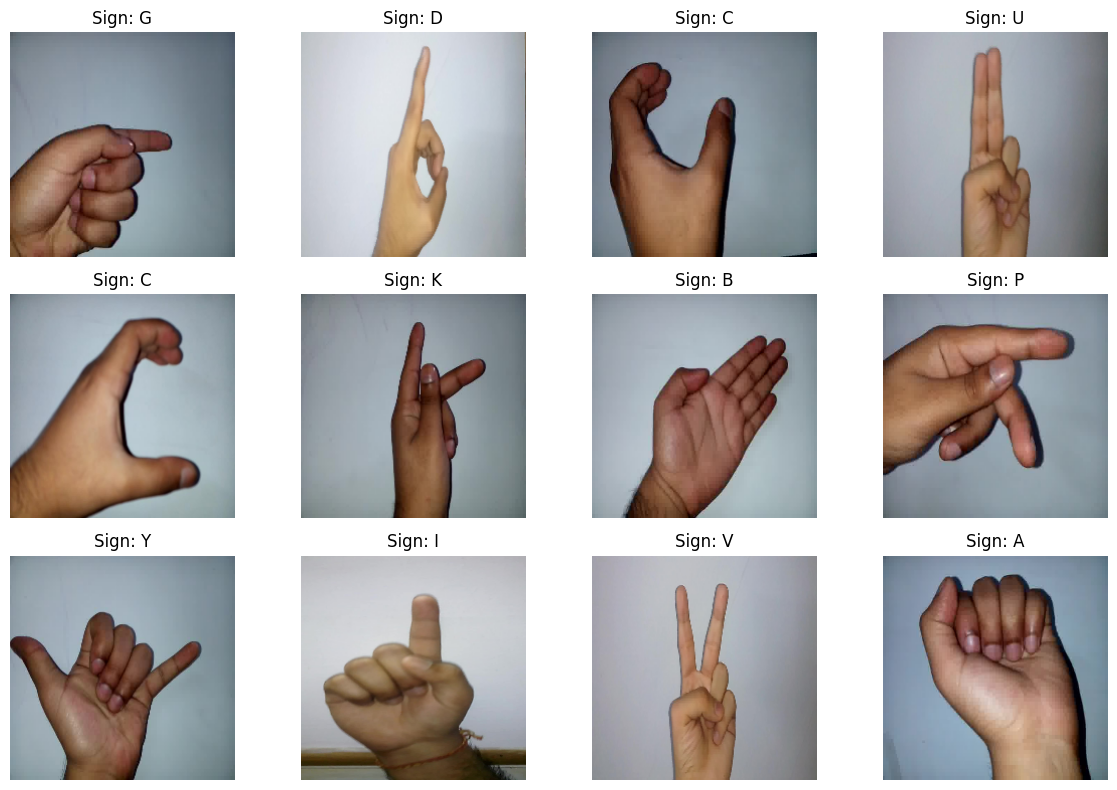

In [74]:
images, batch_labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(12, len(images))):

    plt.subplot(3, 4, i + 1)

    img = images[i].numpy()

    plt.imshow(np.clip(img, 0, 255).astype("uint8"))

    label_idx = batch_labels[i].numpy()

    plt.title(f"Sign: {class_names[label_idx]}")

    plt.axis("off")

plt.tight_layout()
plt.show()

### Model Development – MobileNetV2
MobileNetV2 was selected as the base architecture for the Indian Sign Language recognition task.

MobileNetV2 is a lightweight CNN architecture designed to extract meaningful visual features while maintaining computational efficiency.

Transfer learning was used to leverage the pretrained feature-extraction capabilities of MobileNetV2 and adapt the architecture for the 24-class classification problem.

The model was configured to produce 24 output predictions, corresponding to the 24 sign categories.

In [75]:
# Create a fresh pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("Input shape:", base_model.input_shape)
print("Output shape:", base_model.output_shape)
print("Trainable:", base_model.trainable)

Input shape: (None, 224, 224, 3)
Output shape: (None, 7, 7, 1280)
Trainable: False


In [76]:
#Data Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")



In [77]:
# Check the current base model
print("Base model input:", base_model.input_shape)
print("Base model output:", base_model.output_shape)

# Test it with one batch of preprocessed images
images, labels = next(iter(train_ds))

processed_images = preprocess_input(
    tf.cast(images, tf.float32))

features = base_model(processed_images, training=False)

print("\nInput to MobileNetV2:", processed_images.shape)
print("Output from MobileNetV2:", features.shape)

Base model input: (None, 224, 224, 3)
Base model output: (None, 7, 7, 1280)

Input to MobileNetV2: (32, 224, 224, 3)
Output from MobileNetV2: (32, 7, 7, 1280)


In [78]:
# Build the model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),

    # 1. Augmentation
    data_augmentation,

    # 2. Normalize pixels to approximately [-1, 1]
    layers.Lambda(preprocess_input),

    # 3. Pretrained feature extraction
    base_model,

    # 4. Feature pooling
    layers.GlobalAveragePooling2D(),

    # 5. Regularization
    layers.Dropout(0.3),

    # 6. Classify 24 sign-language classes
    layers.Dense(24, activation="softmax")
])

### Model Training
The prepared training dataset was used to train the classification model, while the validation dataset was used to monitor performance.

Training callbacks were incorporated:
- EarlyStopping: Stops training when the monitored validation performance stops improving.
- ModelCheckpoint: Saves the best-performing model weights.
- ReduceLROnPlateau: Reduces the learning rate when validation performance stops improving.
These callbacks help manage training and reduce unnecessary training iterations.

In [79]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

Model input: (None, 224, 224, 3)
Model output: (None, 24)


In [89]:
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_dir / "best_indisignlang_v2.keras"),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
108/109 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.9951 - loss: 0.0415
Epoch 1: val_loss improved from None to 0.04963, saving model to checkpoints/best_indisignlang_v2.keras

Epoch 1: finished saving model to checkpoints/best_indisignlang_v2.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 123ms/step - accuracy: 0.9948 - loss: 0.0393 - val_accuracy: 0.9933 - val_loss: 0.0496 - learning_rate: 2.0000e-04
Epoch 2/30
108/109 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9956 - loss: 0.0395
Epoch 2: val_loss improved from 0.04963 to 0.04664, saving model to checkpoints/best_indisignlang_v2.keras

Epoch 2: finished saving model to checkpoints/best_indisignlang_v2.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 16s 81ms/step - accuracy: 0.9951 - loss: 0.0391 - val_accuracy: 0.9933 - val_loss: 0.0466 - learning_rate: 2.0000e-04
Epoch 3/30
108/109 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9963 - loss: 0.0345
Epoch 3: val_loss improved from 0.04664 to 0.04481, saving model to checkpoints/best_

### Evaluation
After training, the model was evaluated using the independent test dataset.

The following metrics were selected:
- Accuracy
- Precision
- Recall
- F1-score
- Loss
A confusion matrix and classification report were also used to examine class-wise prediction performance and identify misclassified images.

In [90]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.9960 - loss: 0.0433
Test Loss: 0.0433
Test Accuracy: 99.60%


In [91]:
# Check number of output classes
print("Model output classes:", model.output_shape[-1])
print("Dataset classes:", len(class_names))

# Evaluate model on unseen test dataset
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\nTEST DATASET PERFORMANCE")
print("------------------------")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print("Total images:", total)
print("Correct predictions:", correct)
print("Accuracy:", correct / total)
print(classification_report(all_true, all_pred, digits=4))

Model output classes: 24
Dataset classes: 24
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.9960 - loss: 0.0433

TEST DATASET PERFORMANCE
------------------------
Test Loss     : 0.0433
Test Accuracy : 99.60%
Total images: 748
Correct predictions: 737
Accuracy: 0.9852941176470589
              precision    recall  f1-score   support

           0     0.9189    1.0000    0.9577        34
           1     1.0000    1.0000    1.0000        28
           2     1.0000    1.0000    1.0000        36
           3     1.0000    1.0000    1.0000        21
           4     1.0000    1.0000    1.0000        34
           5     0.9737    1.0000    0.9867        37
           6     1.0000    1.0000    1.0000        29
           7     1.0000    1.0000    1.0000        22
           8     1.0000    1.0000    1.0000        29
           9     1.0000    1.0000    1.0000        39
          10     1.0000    1.0000    1.0000        18
          11     0.8718    1.0000    0.9315        34
         

In [92]:
print("CLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    )
)

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

           A       0.92      1.00      0.96        33
           B       1.00      1.00      1.00        26
           C       1.00      1.00      1.00        40
           D       1.00      1.00      1.00        23
           E       1.00      1.00      1.00        32
           F       1.00      1.00      1.00        35
           G       1.00      1.00      1.00        33
           H       1.00      1.00      1.00        22
           I       1.00      1.00      1.00        27
           K       1.00      1.00      1.00        29
           L       1.00      1.00      1.00        21
           M       0.89      1.00      0.94        39
           N       1.00      0.92      0.96        38
           O       1.00      1.00      1.00        43
           P       1.00      1.00      1.00        44
           Q       1.00      1.00      1.00        41
           R       1.00      1.00    

In [93]:
# Find incorrect predictions
wrong_indices = np.where(y_true != y_pred)[0]

print("Total test images:", len(y_true))
print("Correct predictions:", np.sum(y_true == y_pred))
print("Incorrect predictions:", len(wrong_indices))

print(
    "Misclassification percentage:",
    round(len(wrong_indices) / len(y_true) * 100, 2),
    "%"
)

Total test images: 748
Correct predictions: 739
Incorrect predictions: 9
Misclassification percentage: 1.2 %


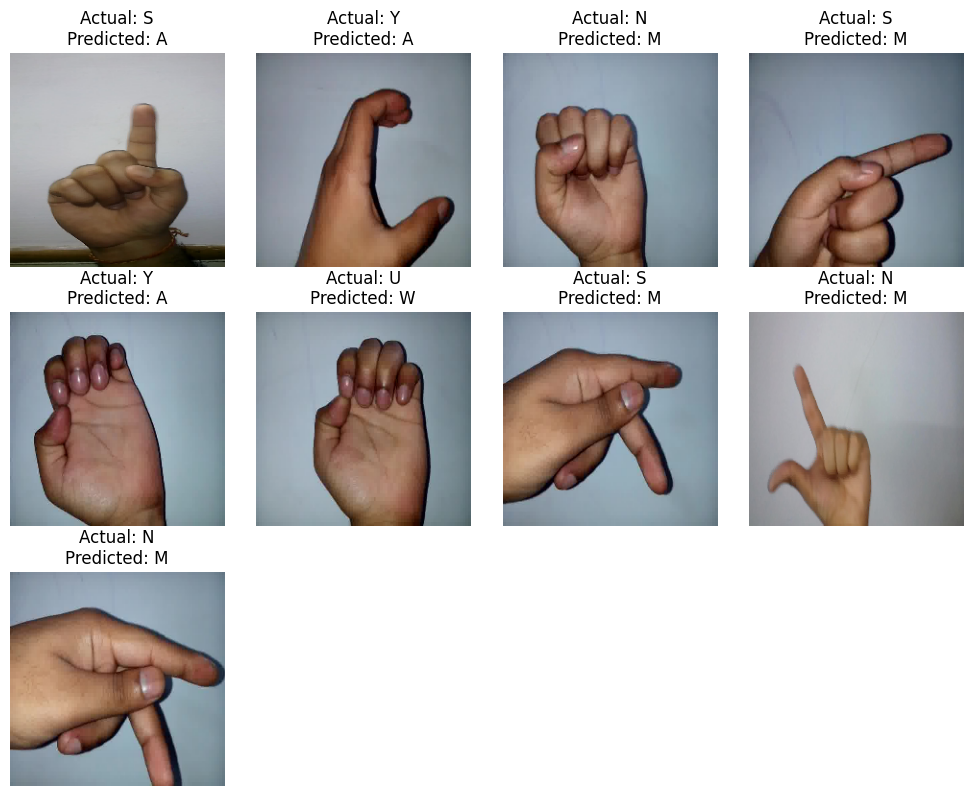

In [94]:
num_images = min(12, len(wrong_indices))

plt.figure(figsize=(10, 8))

for i, idx in enumerate(wrong_indices[:num_images]):

    img_path = X_test[idx]

    img = tf.io.decode_image(
        tf.io.read_file(img_path),
        channels=3,
        expand_animations=False
    )

    img = tf.image.resize(img, IMG_SIZE)

    plt.subplot(3, 4, i + 1)

    plt.imshow(tf.cast(img, tf.uint8))

    plt.title(
        f"Actual: {class_names[y_true[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [95]:
results = {
    "Metric": [
        "Test Accuracy",
        "Test Precision (Weighted)",
        "Test Recall (Weighted)",
        "Test F1-Score (Weighted)",
        "Test Loss"
    ],

    "Score": [
        round(accuracy * 100, 2),
        round(precision * 100, 2),
        round(recall * 100, 2),
        round(f1 * 100, 2),
        round(test_loss, 4)
    ]
}

results_df = pd.DataFrame(results)

print("FINAL MODEL EVALUATION")
display(results_df)

FINAL MODEL EVALUATION


,Metric,Score
0,Test Accuracy,98.8000
1,Test Precision (Weighted),98.9100
2,Test Recall (Weighted),98.8000
3,Test F1-Score (Weighted),98.8000
4,Test Loss,0.0433


## 4. Results and Model Performance

The trained MobileNetV2 model demonstrated strong classification performance.
Provisional test results
98.80%
Test accuracy

98.91%
Weighted precision

98.80%
Weighted recall

98.80%
Weighted F1-score



Test loss
0.0433

Test images
748

Correct predictions
739 (provisional)

Incorrect predictions
9 (provisional)


Interpretation of results
Accuracy – 98.80%

The model correctly classified approximately 98.8% of the test images, demonstrating strong predictive performance on the test dataset.

Precision – 98.91%

The weighted precision indicates that the model's predicted sign categories were highly accurate overall.

Recall – 98.80%

The weighted recall indicates that the model successfully identified most of the actual sign categories represented in the test dataset.

F1-score – 98.80%

The weighted F1-score demonstrates a strong balance between precision and recall.

Test loss – 0.0433

The relatively low test loss indicates that the model's predictions have low classification error under the loss function used during training.
Prediction error analysis
The initial error analysis reported nine incorrectly classified images out of 748 test images.

These misclassifications can be further investigated using the confusion matrix and incorrect prediction visualizations.

This analysis helps identify signs that may have similar visual characteristics or require further model improvement.

## 5. Project Outcomes

The project achieved the following outcomes:
1. Successfully developed an image-based Indian Sign Language classification system.
2. Prepared a structured image-processing and data-loading pipeline using TensorFlow.
3. Implemented a stratified training, validation and testing strategy.
4. Applied transfer learning using the MobileNetV2 architecture.
5. Achieved promising classification performance on unseen test images.
6. Generated evaluation metrics to measure model performance.
7. Identified incorrectly classified images for further analysis.
The results demonstrate the potential of transfer learning for recognizing Indian Sign Language signs from image data.

## 6. Key Learnings


Through this project, the following technical concepts and practical skills were developed:

1. Image data preprocessing

Learned how to load, decode, resize and prepare image datasets for deep learning applications.

2. Dataset management

Understood the importance of class mapping, stratified splitting and maintaining correct image-label associations.

3. TensorFlow data pipelines

Gained experience using tf.data.Dataset, batching, shuffling, parallel processing and prefetching for efficient data loading.

4. Transfer learning

Understood how pretrained CNN architectures such as MobileNetV2 can be adapted to solve a specific image classification problem.

5. Model training optimization

Learned how callbacks such as EarlyStopping, ModelCheckpoint and ReduceLROnPlateau help manage the training process.

6. Model evaluation

Developed an understanding of accuracy, precision, recall, F1-score, confusion matrices and classification reports.

7. Error analysis

Learned that model evaluation should go beyond overall accuracy by examining individual class performance and incorrect predictions.

## 7. Limitations and Future Improvements

Although the model achieved strong results on the available dataset, some limitations remain.
- The model is currently designed for image-based sign recognition rather than continuous sign-language interpretation.
- Recognition performance on real-world images with different lighting, backgrounds and camera angles requires further testing.
- The current system classifies individual images and does not interpret sequences of gestures.
- The model's performance should be validated using images collected independently from the original dataset.
Future improvements could include:
1. Developing real-time sign recognition using a webcam.
2. Extending the system to recognize continuous sign-language gestures.
3. Testing the model on real-world images collected from different environments.
4. Exploring video-based recognition using CNN-LSTM or other temporal models.
5. Developing a user-friendly interface for sign recognition.


## 8. Conclusion

This project successfully demonstrates the application of deep learning and transfer learning for Indian Sign Language image classification.

By utilizing MobileNetV2, the project developed a classification model capable of identifying 24 different sign categories from image inputs.

The initial test evaluation indicates strong performance, with a reported accuracy of approximately 98.80%, subject to final verification of the evaluation outputs.

The project provided practical experience in image preprocessing, dataset preparation, transfer learning, model training and performance evaluation.

Overall, this work demonstrates the potential of computer vision-based systems to support accessibility and improve communication between ISL users and others.